# Search: Solving a Maze Using a Goal-based Agent

Student Name: [Add your name]

I have used the following AI tools: [list tools]

I understand that my submission needs to be my own work: [your initials]

## Learning Outcomes

* Formulate search problems using key components like initial state, actions, and goal state in a deterministic, fully observable environment.
* Implement the search algorithm BFS for planning paths through mazes.
* Use visualization tools to represent maze paths and support debugging and analysis.

## Instructions

Total Points: Undergrads 10

Complete this notebook. Use the provided notebook cells and insert additional code and markdown cells as needed. Submit the notebook file and the completely rendered notebook with all outputs as a HTML file. 


## Introduction

In this exercise, we will implement the planning function for a type of goal-based agent called a __planning agent__. The planning function uses a map it is given to plan a path through the maze from the starting location $S$ to the goal location $G$. We will only focus on the planning function, so you do not need to implement an environment, just use the map to search for a path to solve the maze. 

Once the plan is made, the agent in a deterministic environment (i.e., the transition function is deterministic with the outcome of each state/action pair fixed and no randomness) can just follow the plan step-by-step and does not need to care about the percepts.
This is also called an **[open-loop system](https://en.wikipedia.org/wiki/Open-loop_controller).**
The execution phase is trivial and can be executed using a model-based reflex agent 
that ignores all percepts and just follows the plan. I will show you a short example, but you do not implement it in this exercise.

Given that the agent has a complete and correct map, the environment is **fully observable, discrete, deterministic, and known.** 
Remember:

* **Fully observable** means that the agent can see its state and what the available actions are. That means the **percepts contain the complete current state.**
Here, during planning, the agent always sees its x and y coordinates on the map and
also seeks when it has reached the goal state. 
* **Discrete** means that we have a **finite set of states.** The maze has a finite set 
of squares the agent can be in.
* **Deterministic** means that the **transition function contains no randomness.** An action in a state will always produce the same result. Going south from the start state always will lead to the same square.
* **Know** means that the agent **knows the complete transition function.** The 
agent has the map and therefore knows how its position changes when it walks in a direction.

Tree search algorithm implementations that you find online typically come from data structures courses and have a different aim than AI tree search. These algorithms assume that you already have a tree in memory. We are interested in dynamically creating a search tree with the aim of finding a good/the best path from the root note to the goal state. Follow the pseudo code presented in the text book (and replicated in the slides) closely. Ideally, we would like to search only a small part of the maze, i.e., create a search tree with as few nodes as possible. 

Several mazes for this exercise are stored as text files. We need to make sure that they are locally available.

In [1]:
import urllib.request
import os

def download(file, base_url):
    if not os.path.exists(file):
        urllib.request.urlretrieve(base_url + file, file)

base_url = "https://raw.githubusercontent.com/mhahsler/Introduction_to_Artificial_Intelligence/refs/heads/master/Search/"
download("maze_helper.py", base_url)

mazes = ["small_maze.txt", "large_maze.txt", "open_maze.txt", "empty_maze.txt"]
for maze in mazes:
    download(maze, base_url)

Here is the small example maze:

In [2]:
with open("small_maze.txt", "r") as f:
    maze_str = f.read()
print(maze_str)

XXXXXXXXXXXXXXXXXXXXXX
X XX        X X      X
X    XXXXXX X XXXXXX X
XXXXXX     S  X      X
X    X XXXXXX XX XXXXX
X XXXX X         X   X
X        XXX XXX   X X
XXXXXXXXXX    XXXXXX X
XG         XX        X
XXXXXXXXXXXXXXXXXXXXXX



**Note:** If you get an error here that the file cannot be found, then you need to download it. See [HOWTO Work on Assignments.](https://github.com/mhahsler/CS7320-AI/blob/master/HOWTOs/working_on_assignments.md)

## Parsing and pretty printing the maze

The maze can also be displayed in color using code in the module [maze_helper.py](maze_helper.py). The code parses the string representing the maze and converts it into a `numpy` 2d array which you can use in your implementation. Position are represented as a 2-tuple of the form `(row, col)`. 

In [3]:
import maze_helper as mh

maze = mh.parse_maze(maze_str)

# look at a position in the maze by subsetting the 2d array
print("Position(0,0):", maze[0, 0])

# there is also a helper function called `look(maze, pos)` available
# which uses a 2-tuple for the position.
print("Position(8,1):", mh.look(maze, (8, 1)))

Position(0,0): X
Position(8,1): G


A helper function to visualize the maze is also available.

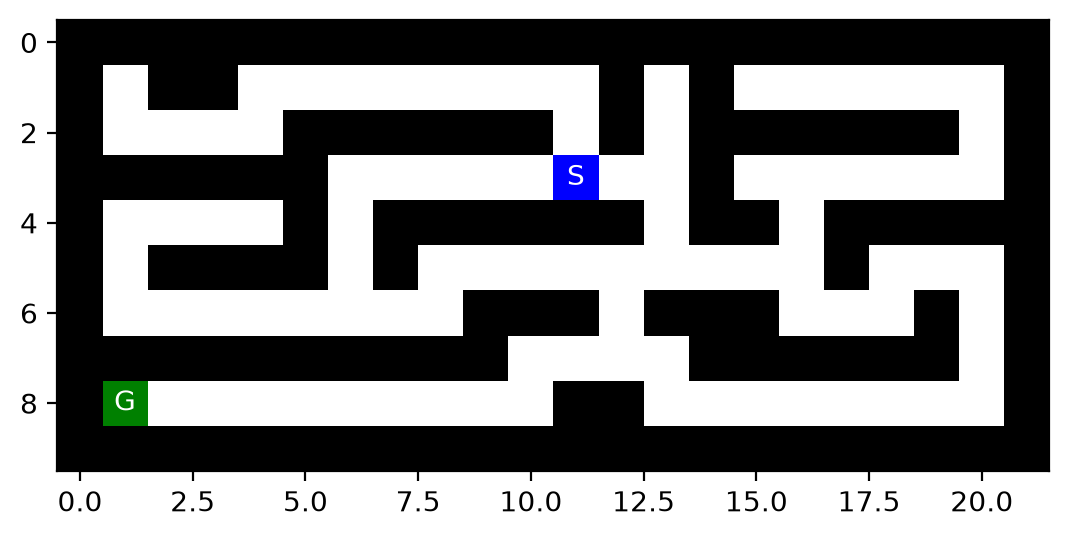

In [4]:
%matplotlib inline
%config InlineBackend.figure_format = 'retina'
# use higher resolution images in notebooks

mh.show_maze(maze)

Find the `(x,y)` position of the start and the goal using the helper function `find_pos()`

In [5]:
print("Start location:", mh.find_pos(maze, what = "S"))
print("Goal location:", mh.find_pos(maze, what = "G"))

Start location: (np.int64(3), np.int64(11))
Goal location: (np.int64(8), np.int64(1))


Helper function documentation.

In [6]:
help(mh)

Help on module maze_helper:

NAME
    maze_helper

DESCRIPTION
    Code for the Maze Assignment
    Usage:
        import maze_helper as mh
        mh.show_some_mazes()

FUNCTIONS
    animate_maze(result, repeat=False)
        (Experimental) Build an animation from a list of mazes.

        Parameters:
            result: a list with the elements path, reached, actions and maze_anim with a list of maze arrays that contain what you want to visualize.
            repeat: if True, the animation will repeat.

    find_pos(maze, what='S')
        Find start/goal in a maze and returns the first one.
        Caution: there is no error checking!

        Parameters:
            maze: a array with characters produced by parse_maze()
            what: the letter to be found ('S' for start and 'G' for goal)

        Returns:
            a tupple (x, y) for the found position.

    look(maze, pos)
        Look at the label of a square with the position as an array of the form (x, y).

        Para

You will need to make a local copy of the module file [maze_helper.py](maze_helper.py) in the same folder where your notebook is.

## An Example for a Planning Agent

I will show you here how to implement a simple agent that uses a random plan. It will not solve the maze, but show you how the mechanics work.

First, we define a generic planning agent that fist plans, and then executes the plan step-by-step. 

In [7]:
class Planning_Agent:
    def __init__(self, maze, start, goal, planning_function):
        self.maze = maze
        self.start = start
        self.goal = goal
        self.planning_function = planning_function
        self.plan = None
        self.progress = None

    def act(self):
        # plan if no plan exists
        if self.plan is None:
            print("Planning...")
            self.plan = self.planning_function(self.maze, self.start, self.goal)
            self.progress = 0
        
        # check if plan is completed
        if self.progress >= len(self.plan):        
            raise Exception("Completed Plan. No more planned actions")
        
        # follow the plan
        action = self.plan[self.progress]
        print(f"Following plan... step {self.progress}: {action}")

        self.progress += 1
        return action

Next, we define the planning function. This function is what you will implement in this assignment.  

In [8]:
import numpy as np

def plan_random(maze, start, goal):
    """Create a random plan with 10 steps"""
    plan = np.random.choice(["N", "E", "S", "W"], size=10, replace=True).tolist()
    return plan

plan_random(maze, (1,1), (8,8))

['W', 'N', 'W', 'W', 'S', 'E', 'W', 'W', 'S', 'W']

This planning function is not great and will not produce a plan that solves the maze. Your planning functions will do better.

Finally, we can create the planning agent, give it the planning function and implement a simple environment that asks it 11 times for an action.

In [9]:
my_agent = Planning_Agent(maze, mh.find_pos(maze, what = "S"), mh.find_pos(maze, what = "G"), plan_random)

def environment(agent_function, steps):
    for _ in range(steps):
        try:
            agent_function()
        except Exception as e:
            print(f"Agent exception: {e}")

environment(my_agent.act, steps=11)

Planning...
Following plan... step 0: N
Following plan... step 1: W
Following plan... step 2: W
Following plan... step 3: W
Following plan... step 4: W
Following plan... step 5: W
Following plan... step 6: E
Following plan... step 7: W
Following plan... step 8: E
Following plan... step 9: W
Agent exception: Completed Plan. No more planned actions


Note: The agent and environment implementation above is just an illustration. You will only implement and experiment with different versions of the planning function.

## Tree structure

To use tree search, you will need to implement a tree data structure in Python. 
Here is an implementation of the basic node structure for the search algorithms (see Fig 3.7 on page 73). I have added a method that extracts the path from the root node to the current node. It can be used to get the path when the search is completed.

In [10]:
class Node:
    def __init__(self, pos, parent, action, cost):
        self.pos = tuple(pos)    # the state; positions are (row,col)
        self.parent = parent     # reference to parent node. None means root node.
        self.action = action     # action used in the transition function (root node has None)
        self.cost = cost         # for uniform cost this is the depth. It is also g(n) for A* search

    def __str__(self):
        return f"Node - pos = {self.pos}; action = {self.action}; cost = {self.cost}"
    
    def get_path_from_root(self):
        """returns nodes on the path from the root to the current node."""
        node = self
        path = [node]
    
        while not node.parent is None:
            node = node.parent
            path.append(node)
        
        path.reverse()
        
        return(path)

If needed, then you can add more fields to the class like the heuristic value $h(n)$ or $f(n)$.

Examples for how to create and use a tree and information on memory management can be found [here](../HOWTOs/trees.ipynb).

# Tasks

The goal is to:

1. Implement the following search algorithm for solving different mazes:
    - Breadth-first search (BFS)

2. Run each of the above algorithms on the 
    - [small maze](small_maze.txt), 
    - [large maze](large_maze.txt), 
    - [open maze](open_maze.txt), and
    - [empty maze](empty_maze.txt).

3. Display each solution by marking every maze square (or state) visited and the squares on the final path.

## General

1. Make sure that you use the latest version of this notebook.
2. Your implementation can use libraries like math, numpy, scipy, but not libraries that implement intelligent agents or complete search algorithms. Try to keep the code simple! In this course, we want to learn about the algorithms and we often do not need to use object-oriented design.
3. You notebook needs to be formatted professionally. 
    - Add additional markdown blocks for your description, comments in the code, add tables and use mathplotlib to produce charts where appropriate
    - Do not show debugging output or include an excessive amount of output.
    - Check that your submitted file is readable and contains all figures.
4. Document your code. Use comments in the code and add a discussion of how your implementation works and your design choices.

## Task 1: Defining the search problem and determining the problem size [2 Points]

Define the components of the search problem:

* Initial state
* Actions
* Transition model
* Goal state
* Path cost

Use verbal descriptions, variables and equations as appropriate. 

*Note:* You can switch the next block from code to Markdown and use formatting.

**Answer**: The agent has the complete map, so the environment is fully observable, discrete, deterministic and known.

Initial state: the square that holds `S`, e.g. `(3, 11)` in the small maze.

Actions: the four moves `N`, `E`, `S`, `W` with offsets `(-1,0)`, `(0,1)`, `(1,0)`, `(0,-1)`, allowed only when the target square is inside the grid and not a wall.

Transition model: `Result(s, a) = s + offset(a)`, deterministic.

Goal state: the square that holds `G`, tested with `s == (r_G, c_G)`.

Path cost: 1 per move, so the path cost is the number of moves.

Every move can be undone with the same cost, so the graph is undirected and contains cycles. BFS handles them with its `reached` set.

Give some estimates for the problem size:

* $d$: depth of the optimal solution
* $m$: maximum depth of tree
* $b$: maximum branching factor

Describe how you would determine these values for a given maze.

**Answer**: `d` (depth of the optimal solution) is measured by running BFS and reading the path length. The lower bound is the Manhattan distance from `S` to `G`.

`m` (maximum depth of the search tree) is measured by the search. With `reached` BFS can never go deeper than the number of states, and in practice it stops at depth `d`, because the goal is found as soon as that level is expanded.

`b` (maximum branching factor) is at most 4, since there are only four directions. Counting the legal moves gives 4 inside the maze, 3 on an edge, 2 in a corner and 1 in a dead end. The effective factor of BFS is smaller because `reached` drops successors that were already generated.

State space sizes of the four mazes:

| maze | grid | n | b_max |
|---|---|---|---|
| small | 10x22 | 94 | 4 |
| large | 37x37 | 647 | 4 |
| open | 23x37 | 684 | 4 |
| empty | 12x12 | 100 | 4 |

## Task 2: Breadth-First Search [5 Points]

Implement this simple search strategies. Follow the pseudocode in the textbook/slides. You can use the tree structure shown above to extract the final path from your solution.

Read the following **important note** carefully:
* You can find maze solving implementations online that use the map to store information. While this is an effective idea for this two-dimensional navigation problem, it typically cannot be used for other search problems. Therefore, follow the textbook and **do not store information in the map.** Only store information in the tree created during search, and use the `reached` and `frontier` data structures where appropriate.


In [11]:
import time
from collections import deque

ACTIONS = ("N", "E", "S", "W")
DIRS = {"N": (-1, 0), "E": (0, 1), "S": (1, 0), "W": (0, -1)}

# measurements of the last BFS run, used by the next cell
RESULTS = {}


def move(maze, pos, action):
    """Successor of pos for action, or None when the move is not allowed."""
    r, c = pos
    dr, dc = DIRS[action]
    nr, nc = r + dr, c + dc
    if 0 <= nr < maze.shape[0] and 0 <= nc < maze.shape[1] and maze[nr, nc] != "X":
        return (nr, nc)
    return None


def plan_bfs(maze, start, goal, node_limit=1000000):
    """Plan a path with BFS and return the list of actions.

    The frontier is a FIFO queue and `reached` holds the states that were already
    generated. Nothing is written into the maze array.
    """
    start, goal = tuple(int(v) for v in start), tuple(int(v) for v in goal)

    metrics = {"expanded": 0, "max depth": 0, "max frontier": 0, "max memory": 0}
    root = Node(start, None, None, 0)
    frontier = deque([root])
    reached = {start}
    found = root if start == goal else None

    while found is None and frontier:
        if metrics["expanded"] >= node_limit:
            metrics["note"] = "node budget exhausted"
            break
        node = frontier.popleft()
        metrics["expanded"] += 1

        for action in ACTIONS:
            child_pos = move(maze, node.pos, action)
            if child_pos is None or child_pos in reached:
                continue
            child = Node(child_pos, node, action, node.cost + 1)
            metrics["max depth"] = max(metrics["max depth"], child.cost)
            if child_pos == goal:
                found = child
                break
            reached.add(child_pos)
            frontier.append(child)

        metrics["max frontier"] = max(metrics["max frontier"], len(frontier))
        metrics["max memory"] = max(metrics["max memory"], len(frontier) + len(reached))

    plan = []
    if found is not None:
        nodes = found.get_path_from_root()
        plan = [n.action for n in nodes[1:]]

    metrics["path length"] = found.cost if found else None
    metrics["path"] = [n.pos for n in found.get_path_from_root()] if found else []
    metrics["reached"] = set(reached)
    metrics["frontier"] = {n.pos for n in frontier}
    return plan, metrics


def plan_and_record(maze, start, goal, name):
    plan, metrics = plan_bfs(maze, start, goal)
    RESULTS[name] = metrics
    return plan


plan = plan_and_record(maze, mh.find_pos(maze, "S"), mh.find_pos(maze, "G"), "small")
print("small maze:", len(plan), "actions, cost", RESULTS["small"]["path length"])
print("actions:", plan)

small maze: 19 actions, cost 19
actions: ['E', 'E', 'S', 'S', 'W', 'S', 'S', 'W', 'W', 'S', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W']


The result of the planning function is a sequence of actions. Fill out the following table:

| maze | path length | # of nodes expanded |
|-----------|-----------|------------------|
| small     | 19        | 90               |
| large     | 210       | 618              |
| open      | 54        | 679              |
| empty     | 14        | 92               |

Visualize the found path for each maze. You can look at the `show_maze()` function in [maze_helper.py](maze_helper.py) to see how you can visualize the path.

The next cell runs BFS on the four mazes and draws each solution, using `.` for the squares that were generated, `F` for the squares still in the frontier and `P` for the final path. The plan for every maze is printed above its figure.

maze               path length        # expanded  max depth  max frontier
small_maze.txt              19                90         19             9
large_maze.txt             210               618        210             8
open_maze.txt               54               679         54            25
empty_maze.txt              14                92         14            12

small_maze.txt actions: E -> E -> S -> S -> W -> S -> S -> W -> W -> S -> W -> W -> W -> W -> W -> W -> W -> W -> W


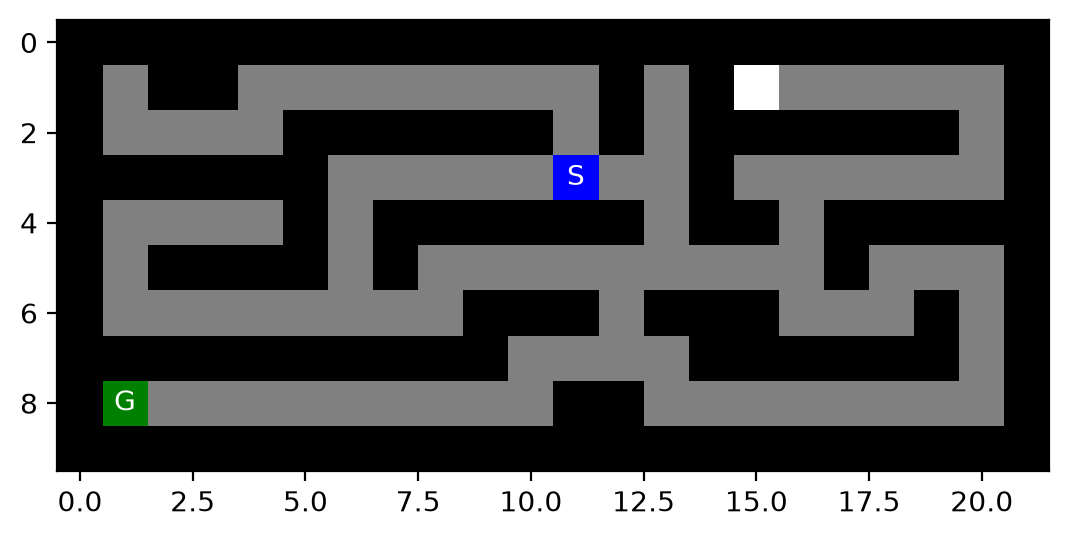


large_maze.txt actions: N -> N -> W -> W -> W -> W -> N -> N -> W -> W -> S -> S -> W -> W -> W -> W -> W -> W -> W -> W -> W -> W -> W -> W -> W -> W -> N -> N -> E -> E -> N -> N -> W -> W -> N -> N -> N -> N -> N -> N -> E -> E -> E -> E -> E -> E -> S -> S -> E -> E -> N -> N -> E -> E -> E -> E -> N -> N -> E -> E -> S -> S -> E -> E -> N -> N -> N -> N -> N -> N -> E -> E -> E -> E -> N -> N -> N -> N -> N -> N -> N -> N -> N -> N -> W -> W -> S -> S -> W -> W -> W -> W -> S -> S -> S -> S -> S -> S -> W -> W -> S -> S -> S -> S -> W -> W -> N -> N -> W -> W -> W -> W -> W -> W -> W -> W -> W -> W -> W -> W -> N -> N -> E -> E -> N -> N -> N -> N -> N -> N -> E -> E -> E -> E -> E -> E -> N -> N -> N -> N -> N -> N -> N -> N -> W -> W -> W -> W -> W -> W -> S -> S -> W -> W -> W -> W -> S -> S -> S -> S -> E -> E -> S -> S -> W -> W -> W -> W -> W -> W -> W -> W -> W -> W -> S -> S -> S -> S -> S -> S -> S -> S -> S -> S -> E -> E -> S -> S -> S -> S -> W -> W -> S -> S -> S -> 

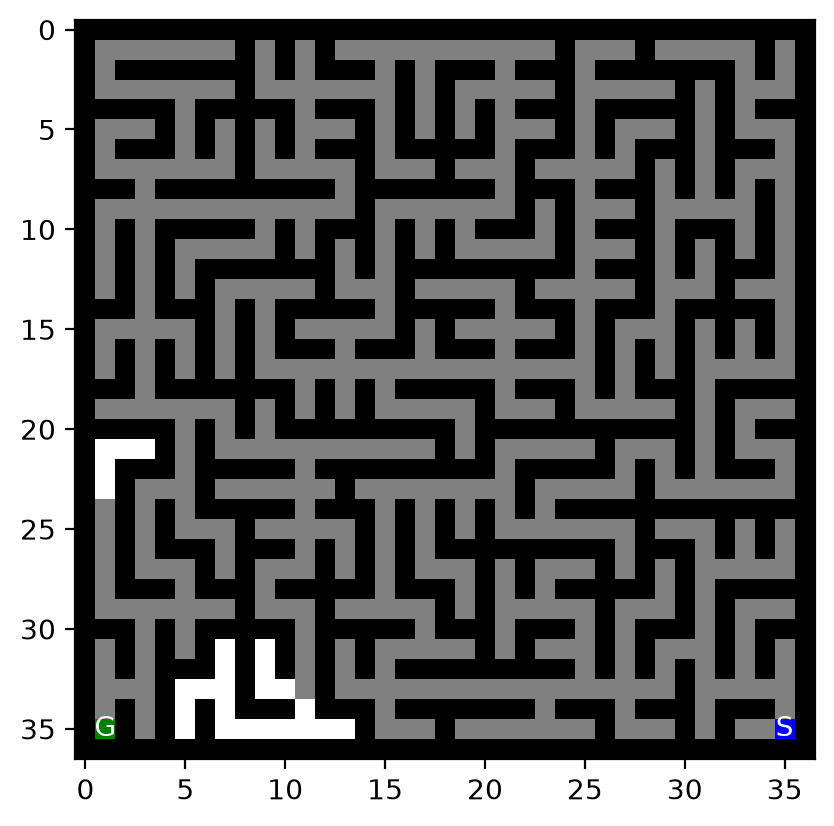


open_maze.txt actions: S -> S -> S -> S -> S -> W -> W -> W -> W -> W -> W -> W -> W -> W -> W -> W -> W -> W -> W -> W -> W -> S -> S -> S -> S -> S -> S -> S -> S -> S -> S -> S -> S -> S -> S -> S -> W -> W -> W -> W -> W -> W -> W -> W -> W -> W -> W -> W -> W -> W -> W -> W -> W -> W


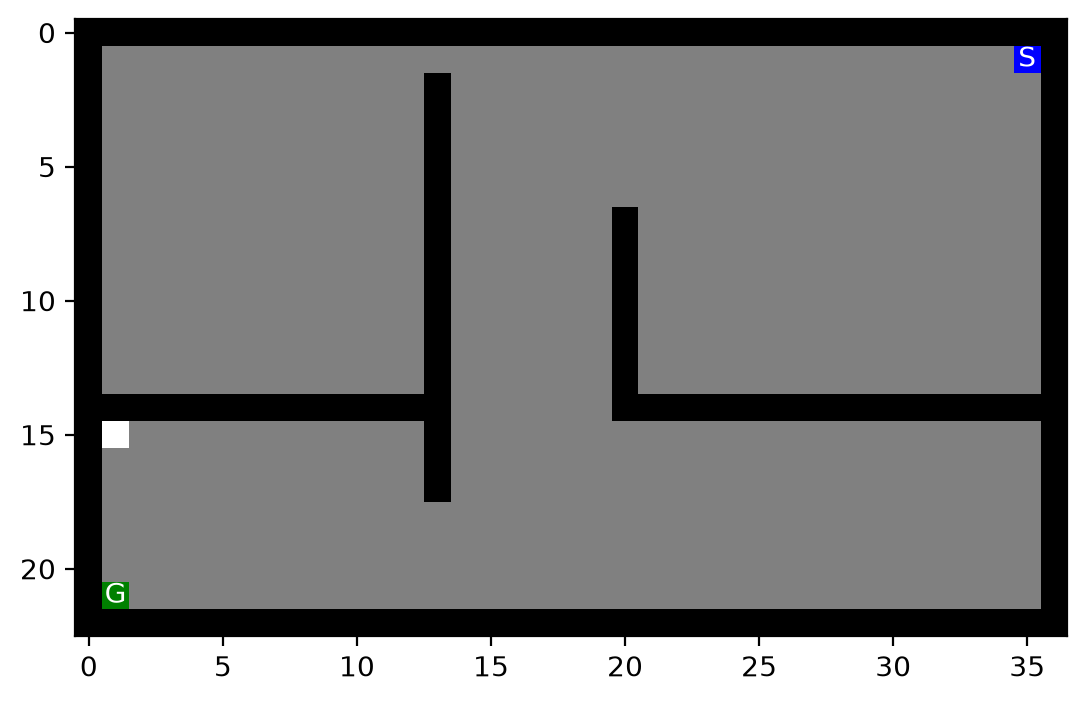


empty_maze.txt actions: N -> N -> N -> N -> N -> N -> N -> E -> E -> E -> E -> E -> E -> E


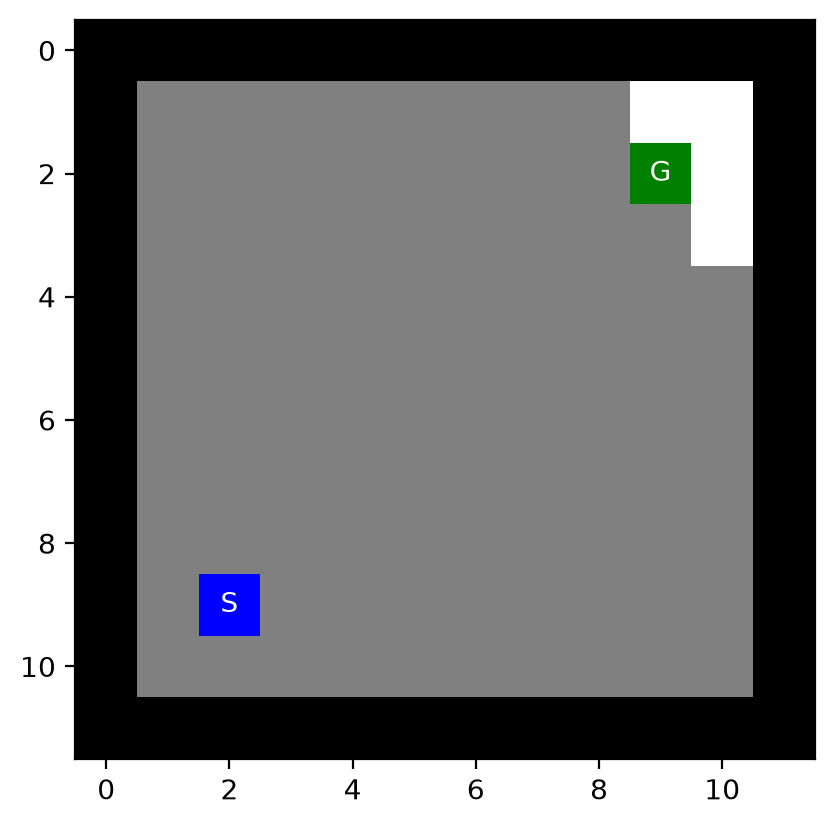


Legend: . explored, F frontier, P final path, S start, G goal.


In [12]:
import numpy as np
import matplotlib.pyplot as plt

MAZE_FILES = ["small_maze.txt", "large_maze.txt", "open_maze.txt", "empty_maze.txt"]

maze_data = {}
for name in MAZE_FILES:
    with open(name, "r") as f:
        maze = mh.parse_maze(f.read())
    start = tuple(int(v) for v in mh.find_pos(maze, "S"))
    goal = tuple(int(v) for v in mh.find_pos(maze, "G"))
    maze_data[name] = (maze, start, goal)
print("{:<18}{:>12}{:>18}{:>11}{:>14}".format(
    "maze", "path length", "# expanded", "max depth", "max frontier"))
_plans = {}
for name, (maze, start, goal) in maze_data.items():
    _plans[name] = plan_and_record(maze, start, goal, name)
    m = RESULTS[name]
    print("{:<18}{:>12}{:>18}{:>11}{:>14}".format(
        name, m["path length"], m["expanded"], m["max depth"], m["max frontier"]))


def annotate_maze(maze, start, goal, m):
    """Copy of the maze with explored squares, frontier and the final path."""
    shown = np.copy(maze)
    for pos in m["reached"]:
        if shown[pos] == " ":
            shown[pos] = "."
    for pos in m["frontier"]:
        if shown[pos] == " ":
            shown[pos] = "F"
    for pos in m["path"]:
        if shown[pos] == " ":
            shown[pos] = "P"
    shown[start] = "S"
    shown[goal] = "G"
    return shown


for name, (maze, start, goal) in maze_data.items():
    print()
    print(name, "actions:", " -> ".join(a for a in _plans[name]))
    mh.show_maze(annotate_maze(maze, start, goal, RESULTS[name]))

print()
print("Legend: . explored, F frontier, P final path, S start, G goal.")

# Task 3: Discussion [3 Points] 

Is your implementation complete and optimal? Explain why. What is the time and space complexity of each of **your** implementation?

**Answer**: BFS is complete. The state space is finite and `reached` generates every state at most once, so a reachable goal is always found. It is also optimal for this problem, because every move costs 1 and the FIFO frontier expands nodes in non-decreasing order of depth, so the goal is first reached along a shortest path. That argument depends on the uniform cost; with different step costs the same code would have to be replaced by uniform-cost search.

The time complexity is O(b^d): every node above the goal depth is expanded, with `b` the branching factor and `d` the depth of the optimal solution. The space complexity is O(b^d) as well, because the frontier holds about one whole level of the tree and `reached` holds every state that was generated. Space is the binding limit in practice. On the four mazes the measured numbers were 90, 618, 679 and 92 expanded nodes for paths of 19, 210, 54 and 14 moves.

How would the planning improve if you use informed search with A* search and the Euclidean distance to the goal as the heuristic? What would the algorithm do differently?

**Answer**: A* keeps the same tree search but changes the priority of the frontier from depth to f(n) = g(n) + h(n), where g(n) is the path cost so far and h(n) = sqrt((r - r_G)^2 + (c - c_G)^2) is the straight line distance to the goal. Three things change.

The frontier becomes a priority queue ordered by f instead of a FIFO queue, and `reached` has to keep the best g found for each state so that a cheaper route can re-open a state. The search becomes directed: BFS expands a uniform ring of nodes around the start, while A* expands the nodes between the start and the goal, so the part of the maze behind the start is mostly never touched. The path it returns is still a shortest path, because the Euclidean distance never overestimates the number of moves that are left.

It is however a weaker heuristic than Manhattan on a four-direction grid: the straight line is always smaller than the number of axis-parallel steps, so A* with Euclidean expands more nodes than A* with Manhattan. In Ex1 on the open maze it expanded 551 nodes against 536, for the same path cost of 54.

Your BFS implementation works fine to solve small mazes. Why would it not work for larger problems with millions of states and 100s of actions? What algorithm could be used then?

**Answer**: BFS stores every state it generates, so its memory is O(b^d). With millions of states and hundreds of actions the frontier alone no longer fits in memory, and the problem is not only size: BFS is blind, so it cannot tell a promising state from a hopeless one and spends the same effort in every direction. At b = 100 and d = 6 the last level already holds 10^12 nodes.

What to use instead: A* or weighted A* when a heuristic is available, because it keeps the optimality for A* while only exploring the part of the space that the heuristic points at; IDA*, which is A* with a depth-first memory and stores only the current path plus the next f threshold; greedy best-first or beam search when a good plan is enough and it does not have to be optimal; or bidirectional search, which grows two frontiers and reduces the exponent to about b^(d/2). Reducing the state space itself, for example by planning on a graph of intersections, is the only change that affects the exponent rather than the constant.